Loading I-JEPA...


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]


Encoding 10 images...
  ✓ labrador: decay=0.87
  ✓ cat: decay=1.45
  ✓ person: decay=1.23
  ✓ bulldog: decay=1.10
  ✓ horse: decay=0.66
  ✓ kitten: decay=0.66
  ✓ landscape: decay=0.56
  ✓ coffee: decay=1.37
  ✓ car: decay=1.10
  ✓ puppy: decay=1.21

Total memories: 10

Running ORIGINAL (unnormalized)...
Running NORMALIZED...

COMPARISON WITH 10 MEMORIES

Memory            α     Original   Normalized
--------------------------------------------
  landscape     0.56       0.1851       0.0170
  kitten        0.66         DEAD       0.0150
  horse         0.66         DEAD       0.0153
  labrador      0.87         DEAD       0.0122
  bulldog       1.10         DEAD       0.0108
  car           1.10         DEAD       0.0106
  puppy         1.21         DEAD       0.0098
  person        1.23         DEAD       0.0102
  coffee        1.37         DEAD       0.0091
  cat           1.45         DEAD       0.0093

Survivors: Original=1/10, Normalized=10/10
Decay rate predicts activation ranki

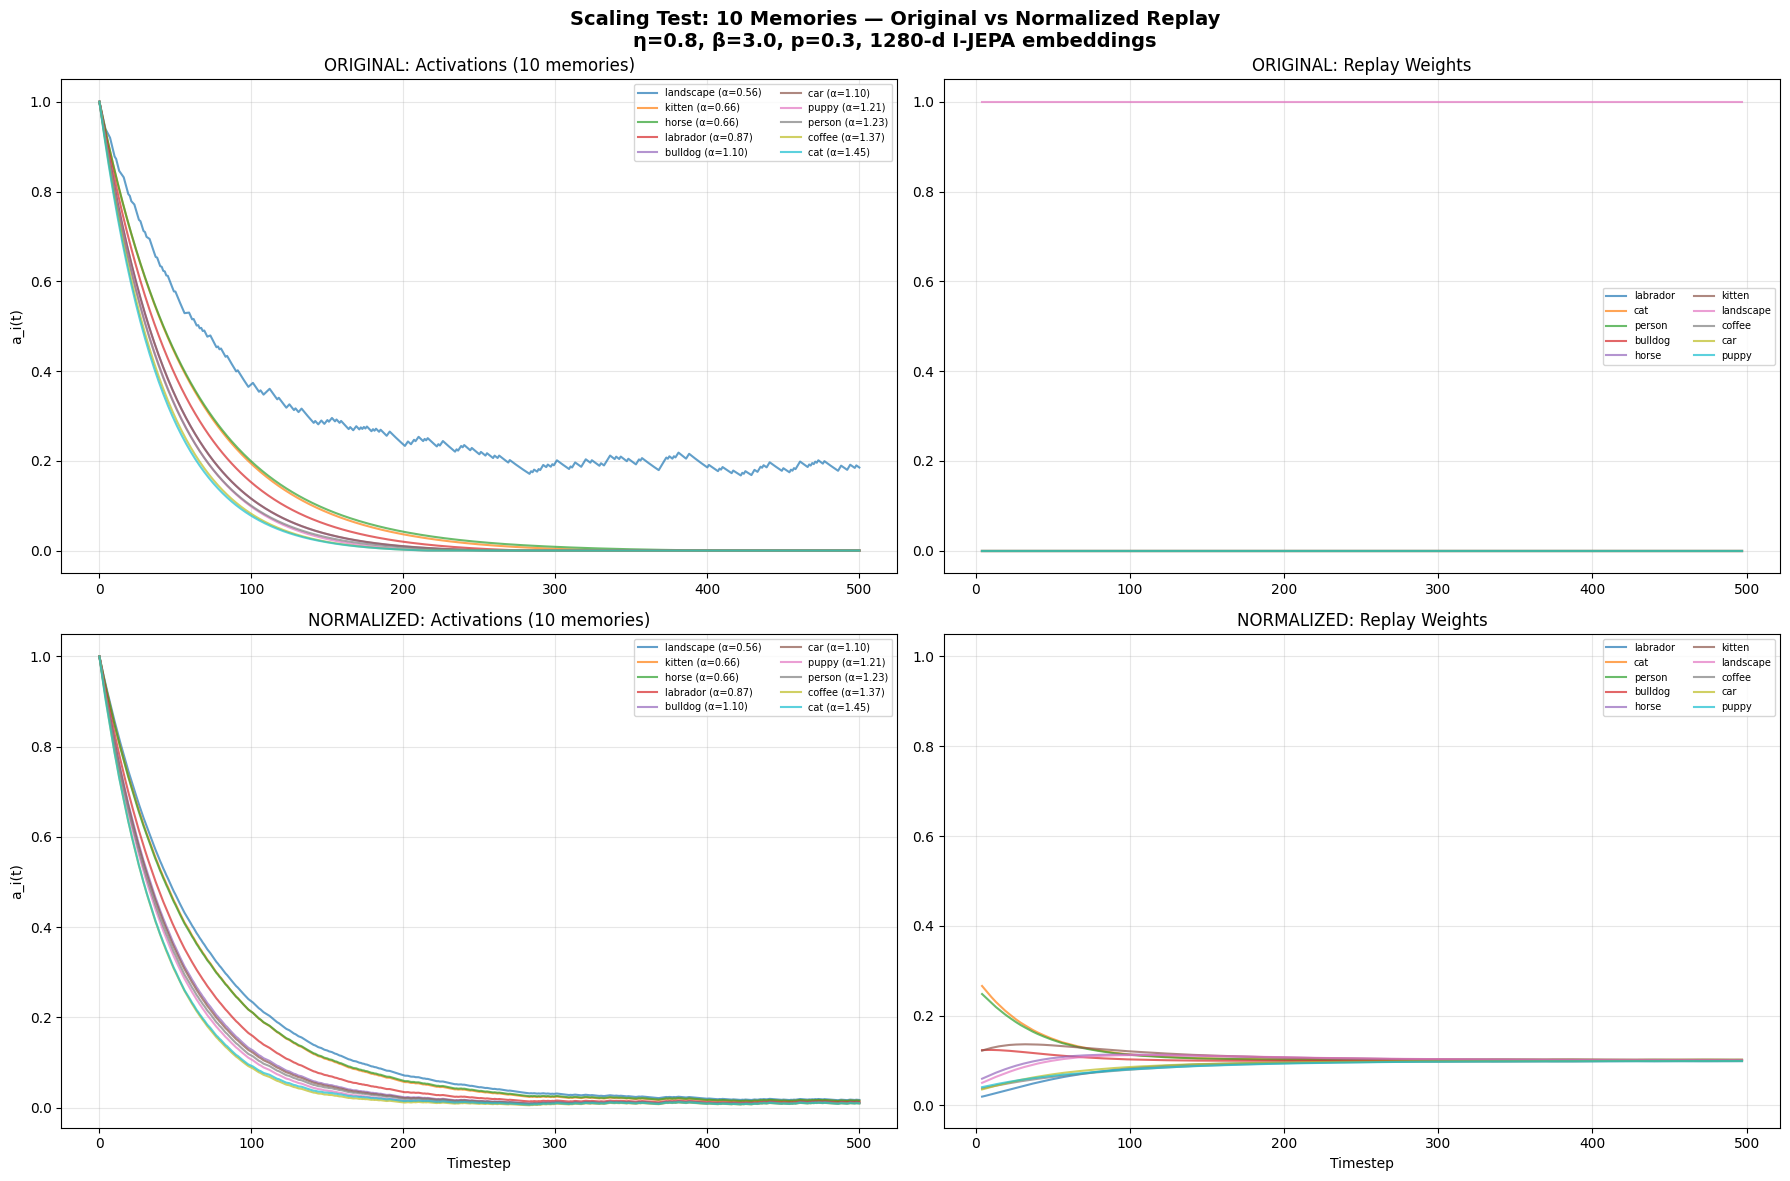

In [3]:
# ============================================================
# SCALED TEST: 10 memories, normalized replay
# Does the balanced regime hold with more memories?
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
from transformers import AutoProcessor, AutoModel
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

model_id = "facebook/ijepa_vith14_1k"
print("Loading I-JEPA...")
processor = AutoProcessor.from_pretrained(model_id)
encoder = AutoModel.from_pretrained(model_id).eval()

@torch.no_grad()
def encode_image(url):
    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(url, headers=headers, stream=True, timeout=15)
    response.raise_for_status()
    img = Image.open(BytesIO(response.content)).convert("RGB")
    inputs = processor(img, return_tensors="pt")
    outputs = encoder(**inputs)
    return outputs.last_hidden_state.mean(dim=1).squeeze()

# 10 diverse images — animals, people, objects, scenes
urls_and_labels = [
    ("https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400", "labrador"),
    ("https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=400", "cat"),
    ("https://images.unsplash.com/photo-1517841905240-472988babdf9?w=400", "person"),
    ("https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=400", "bulldog"),
    ("https://images.unsplash.com/photo-1553284965-83fd3e82fa5a?w=400", "horse"),
    ("https://images.unsplash.com/photo-1518791841217-8f162f1e1131?w=400", "kitten"),
    ("https://images.unsplash.com/photo-1506744038136-46273834b3fb?w=400", "landscape"),
    ("https://images.unsplash.com/photo-1519125323398-675f0ddb6308?w=400", "coffee"),
    ("https://images.unsplash.com/photo-1494976388531-d1058494cdd8?w=400", "car"),
    ("https://images.unsplash.com/photo-1560807707-8cc77767d783?w=400", "puppy"),
]

class DynamicalMemoryScaled:
    def __init__(self, gamma=0.2, delta=0.1, beta=3.0, eta=0.8, h=0.01,
                 normalize_replay=False):
        self.embeddings = []
        self.activations = None
        self.gamma = gamma
        self.delta = delta
        self.beta = beta
        self.eta = eta
        self.h = h
        self.decay_rates = []
        self.normalize_replay = normalize_replay

    def store(self, embedding, decay_rate=1.0):
        self.embeddings.append(embedding.clone())
        self.decay_rates.append(decay_rate)
        N = len(self.embeddings)
        if self.activations is None:
            self.activations = torch.ones(N)
        else:
            self.activations = torch.cat([self.activations, torch.ones(1)])

    def _build_laplacian(self):
        X = torch.stack(self.embeddings)
        X_norm = F.normalize(X, dim=1)
        W = torch.clamp(X_norm @ X_norm.T, min=0)
        W.fill_diagonal_(0)
        D = torch.diag(W.sum(dim=1))
        return D - W

    def _replay_operator(self):
        X = torch.stack(self.embeddings)
        if self.normalize_replay:
            X_n = F.normalize(X, dim=1)
            s = X_n @ (X_n.T @ self.activations)
        else:
            s = X @ (X.T @ self.activations)
        return F.softmax(self.beta * s, dim=0)

    def run(self, steps=500, replay_prob=0.3):
        act_history = [self.activations.clone().numpy()]
        replay_weights_history = []
        replay_steps = []

        for t in range(steps):
            a = self.activations
            N = len(a)
            A = torch.diag(torch.tensor(self.decay_rates, dtype=torch.float32))
            L = self._build_laplacian()

            f_decay = -A @ a
            f_diffusion = -self.gamma * L @ a
            f_inhibition = -self.delta * a.sum() * torch.ones(N)

            S = 1.0 if np.random.random() < replay_prob else 0.0
            Fa = self._replay_operator()
            f_replay = self.eta * S * Fa

            if S > 0:
                replay_weights_history.append(Fa.detach().numpy().copy())
                replay_steps.append(t)

            da_dt = f_decay + f_diffusion + f_inhibition + f_replay
            self.activations = a + self.h * da_dt
            self.activations = torch.clamp(self.activations, min=0)
            act_history.append(self.activations.clone().numpy())

        return {
            'activations': np.array(act_history),
            'replay_weights': np.array(replay_weights_history),
            'replay_steps': np.array(replay_steps),
        }

# ============================================================
# Encode all images
# ============================================================
print("\nEncoding 10 images...")
all_embeddings = []
all_labels = []
all_decays = []

for url, label in urls_and_labels:
    try:
        emb = encode_image(url)
        decay = np.random.uniform(0.5, 1.5)
        all_embeddings.append(emb)
        all_labels.append(label)
        all_decays.append(decay)
        print(f"  ✓ {label}: decay={decay:.2f}")
    except Exception as e:
        print(f"  ✗ {label}: FAILED ({e}), using fallback")
        all_embeddings.append(torch.randn(1280))
        all_labels.append(label)
        all_decays.append(np.random.uniform(0.5, 1.5))

N = len(all_embeddings)
print(f"\nTotal memories: {N}")

# ============================================================
# Run BOTH versions
# ============================================================

# ORIGINAL
torch.manual_seed(42); np.random.seed(42)
mem_orig = DynamicalMemoryScaled(normalize_replay=False)
for emb, decay in zip(all_embeddings, all_decays):
    mem_orig.store(emb, decay)
torch.manual_seed(42); np.random.seed(42)
print("\nRunning ORIGINAL (unnormalized)...")
res_orig = mem_orig.run(steps=500, replay_prob=0.3)

# NORMALIZED
torch.manual_seed(42); np.random.seed(42)
mem_norm = DynamicalMemoryScaled(normalize_replay=True)
for emb, decay in zip(all_embeddings, all_decays):
    mem_norm.store(emb, decay)
torch.manual_seed(42); np.random.seed(42)
print("Running NORMALIZED...")
res_norm = mem_norm.run(steps=500, replay_prob=0.3)

# ============================================================
# RESULTS
# ============================================================
print("\n" + "="*60)
print(f"COMPARISON WITH {N} MEMORIES")
print("="*60)

final_orig = res_orig['activations'][-1]
final_norm = res_norm['activations'][-1]

print(f"\n{'Memory':<12} {'α':>6} {'Original':>12} {'Normalized':>12}")
print("-" * 44)

# Sort by decay rate for clarity
sorted_idx = np.argsort(all_decays)
for i in sorted_idx:
    orig_val = f"{final_orig[i]:.4f}" if final_orig[i] > 0.001 else "DEAD"
    norm_val = f"{final_norm[i]:.4f}" if final_norm[i] > 0.001 else "DEAD"
    print(f"  {all_labels[i]:<12} {all_decays[i]:>5.2f} {orig_val:>12} {norm_val:>12}")

orig_alive = sum(1 for x in final_orig if x > 0.001)
norm_alive = sum(1 for x in final_norm if x > 0.001)
print(f"\nSurvivors: Original={orig_alive}/{N}, Normalized={norm_alive}/{N}")

# Check if decay ranking holds in normalized
norm_pairs = [(all_decays[i], final_norm[i], all_labels[i]) for i in range(N)]
norm_pairs.sort(key=lambda x: x[0])  # sort by decay
activations_sorted = [x[1] for x in norm_pairs]
is_monotonic = all(activations_sorted[i] >= activations_sorted[i+1] - 0.001
                    for i in range(len(activations_sorted)-1))
print(f"Decay rate predicts activation ranking (normalized): {'YES' if is_monotonic else 'NOT PERFECTLY'}")

# ============================================================
# PLOTS
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Top-left: Original activations
ax = axes[0][0]
for i in sorted_idx:
    ax.plot(res_orig['activations'][:, i],
            label=f"{all_labels[i]} (α={all_decays[i]:.2f})", alpha=0.7)
ax.set_title(f"ORIGINAL: Activations ({N} memories)")
ax.set_ylabel("a_i(t)"); ax.legend(fontsize=7, ncol=2); ax.grid(True, alpha=0.3)

# Top-right: Original replay weights
ax = axes[0][1]
rw_o = res_orig['replay_weights']
rs_o = res_orig['replay_steps']
for i in range(N):
    ax.plot(rs_o, rw_o[:, i], label=all_labels[i], alpha=0.7)
ax.set_title("ORIGINAL: Replay Weights")
ax.set_ylim(-0.05, 1.05); ax.legend(fontsize=7, ncol=2); ax.grid(True, alpha=0.3)

# Bottom-left: Normalized activations
ax = axes[1][0]
for i in sorted_idx:
    ax.plot(res_norm['activations'][:, i],
            label=f"{all_labels[i]} (α={all_decays[i]:.2f})", alpha=0.7)
ax.set_title(f"NORMALIZED: Activations ({N} memories)")
ax.set_xlabel("Timestep"); ax.set_ylabel("a_i(t)")
ax.legend(fontsize=7, ncol=2); ax.grid(True, alpha=0.3)

# Bottom-right: Normalized replay weights
ax = axes[1][1]
rw_n = res_norm['replay_weights']
rs_n = res_norm['replay_steps']
for i in range(N):
    ax.plot(rs_n, rw_n[:, i], label=all_labels[i], alpha=0.7)
ax.set_title("NORMALIZED: Replay Weights")
ax.set_xlabel("Timestep")
ax.set_ylim(-0.05, 1.05); ax.legend(fontsize=7, ncol=2); ax.grid(True, alpha=0.3)

fig.suptitle(f"Scaling Test: {N} Memories — Original vs Normalized Replay\n"
             f"η=0.8, β=3.0, p=0.3, 1280-d I-JEPA embeddings",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("scaled_test_10_memories.png", dpi=150, bbox_inches='tight')
plt.show()